# Projet Machine Learning : Réadmission hospitalière des patients diabétiques

**Dataset :** Diabetes 130-US Hospitals for Years 1999-2008 (UCI)
**Démarche :** CRISP-DM (Business Understanding, Data Understanding, Data Exploration, Data Preparation, Segmentation, Classification, Évaluation)

## Plan du notebook
1. Business Understanding
2. Data Understanding
3. Data Exploration
4. Data Preparation (nettoyage, transformation, feature engineering)
5. Segmentation (clustering)
6. Classification
7. Évaluation et interprétation des résultats
8. Conclusion et limites


# 1. Business Understanding

## 1.1 Contexte
Le dataset regroupe **101 766 séjours hospitaliers** de patients diabétiques, collectés dans **130 hôpitaux américains** entre 1999 et 2008, avec **50 variables** : démographie, type d'admission, durée du séjour, examens réalisés, médicaments, diagnostics et issue (réadmission).

Une **réadmission rapide (moins de 30 jours après la sortie)** est un indicateur de qualité de soins reconnu : elle est coûteuse pour le système de santé et révèle souvent une prise en charge incomplète ou une sortie trop précoce.

## 1.2 Problématiques retenues
| Tâche | Problématique | Type |
|---|---|---|
| Segmentation | Existe-t-il des **profils types de séjours/patients** (par exemple jeunes avec peu de traitements vs âgés avec séjours lourds) ? | Non supervisé |
| Classification | Peut-on **prédire si un patient sera réadmis en moins de 30 jours** à partir des informations disponibles à la sortie ? | Supervisé, binaire |

## 1.3 Variable cible
La variable `readmitted` possède 3 modalités : `NO`, `>30`, `<30`. Nous la transformons en **cible binaire** `readmit_30` :
- `1` si réadmission en **moins de 30 jours**
- `0` sinon (`NO` ou `>30`)

**Pourquoi binaire ?** La réadmission précoce est celle qui a un sens métier fort (pénalités financières, qualité des soins). Cela rend aussi l'évaluation plus lisible qu'un problème à 3 classes.

## 1.4 Critères de succès
- Les classes seront **déséquilibrées** (environ 9 à 11 % de réadmissions < 30 jours). L'**accuracy seule est donc trompeuse** : un modèle qui répond toujours "pas de réadmission" aurait environ 89 % d'accuracy.
- Nous suivrons donc surtout le **rappel (recall)** de la classe positive (rater un patient à risque est coûteux), la **précision**, le **F1**, le **ROC-AUC** et le **PR-AUC**.

# 2. Data Understanding

## 2.1 Imports et paramètres

In [37]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import jinja2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (silhouette_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, classification_report, ConfusionMatrixDisplay)
import csv

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

## 2.2 Chargement des données
Le code charge le fichier local `Data/diabetic_data.csv`.

On remarque que les valeurs manquantes sont codées par '?' alors on les changes par NaN.

In [38]:
from pathlib import Path
Data_DIR = Path("./Data")

df_raw = pd.read_csv(Data_DIR / "diabetic_data.csv", keep_default_na=False, na_values=["?"])

df = df_raw.replace("?", np.nan).copy()

print("Dimensions :", df.shape)
df.head()

Dimensions : (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

## 2.3 Dictionnaire des variables (regroupé par famille)

| Famille | Variables | Remarque |
|---|---|---|
| Identifiants | `encounter_id`, `patient_nbr` | Pas de valeur prédictive, mais `patient_nbr` sert à détecter les patients présents plusieurs fois |
| Démographie | `race`, `gender`, `age` (tranches de 10 ans), `weight` | `weight` est presque entièrement manquante |
| Admission / sortie | `admission_type_id`, `discharge_disposition_id`, `admission_source_id`, `time_in_hospital` | Les 3 premiers sont des codes numériques représentant des catégories |
| Activité hospitalière | `num_lab_procedures`, `num_procedures`, `num_medications`, `number_diagnoses` | Variables numériques (comptages) |
| Historique du patient | `number_outpatient`, `number_emergency`, `number_inpatient` | Nombre de visites sur l'année précédente |
| Diagnostics | `diag_1`, `diag_2`, `diag_3` | Codes CIM-9 (très nombreuses modalités) |
| Examens | `max_glu_serum`, `A1Cresult` | Résultats de glycémie et d'HbA1c (ou "None" si non réalisé) |
| Médicaments | 23 colonnes (`metformin`, `insulin`, ...) | Modalités : `No`, `Steady`, `Up`, `Down` |
| Traitement | `change`, `diabetesMed` | Changement de traitement, prescription d'un médicament antidiabétique |
| Cible | `readmitted` | `NO`, `>30`, `<30` |

## 2.4 Fichier de mapping des identifiants (`IDS_mapping.csv`)

Trois colonnes du dataset (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`) sont des **codes numériques**. Le fichier `IDS_mapping.csv` fourni avec le dataset donne leur signification. Il contient **3 tables empilées dans un même CSV**, séparées par une ligne vide : on le lit donc avec un petit parseur qui détecte chaque en-tête.


In [40]:
def load_ids_mapping(path):
    # Lit IDS_mapping.csv : 3 tables empilées, séparées par une ligne vide
    tables, current = {}, None
    with open(path, newline="", encoding="utf-8-sig") as f:
        for row in csv.reader(f):
            if not row or all(cell.strip() == "" for cell in row):
                current = None                      # ligne vide : fin de table
            elif row[0].strip().endswith("_id"):
                current = row[0].strip()            # en-tête : nouvelle table
                tables[current] = {}
            else:
                tables[current][int(row[0])] = row[1].strip()
    return tables

mapping_path = Data_DIR / "IDS_mapping.csv"
if mapping_path is None:
    raise FileNotFoundError("Vérifiez l'emplacement de IDS_mapping.csv.")

ids_tables = load_ids_mapping(mapping_path)
admission_type_labels = ids_tables["admission_type_id"]
discharge_labels = ids_tables["discharge_disposition_id"]
admission_source_labels = ids_tables["admission_source_id"]

for name, table in ids_tables.items():
    print(f"{name:28s} : {len(table)} codes")

admission_type_id            : 8 codes
discharge_disposition_id     : 30 codes
admission_source_id          : 25 codes


### Règles de regroupement (basées sur les descriptions)
Les dizaines de codes sont regroupées en quelques catégories lisibles, afin d'éviter une explosion du nombre de colonnes après encodage One-Hot.

| Variable | Groupes obtenus | Règle |
|---|---|---|
| `admission_type_id` | `Emergency`, `Elective`, `Other`, `Unknown` | Emergency, Urgent et Trauma Center sont fusionnés (même logique d'urgence) ; `Newborn` va dans `Other` |
| `discharge_disposition_id` | `Home`, `HomeHealth`, `Facility`, `Other`, `Unknown`, `Deceased_Hospice` | `Expired` et `Hospice` sont repérés par leur description et seront **exclus** (section 4.1) ; tout transfert vers un établissement est `Facility` |
| `admission_source_id` | `Emergency`, `Referral`, `Transfer`, `Other`, `Unknown` | Les 3 types de référence (médecin, clinique, HMO) sont fusionnés ; naissances et police vont dans `Other` |

In [41]:
UNKNOWN_LABELS = {"NULL", "Not Available", "Not Mapped", "Unknown/Invalid"}

def group_admission_type(desc):
    if desc in UNKNOWN_LABELS:
        return "Unknown"
    if desc in ("Emergency", "Urgent", "Trauma Center"):
        return "Emergency"
    if desc == "Elective":
        return "Elective"
    return "Other"

def group_discharge(desc):
    if desc in UNKNOWN_LABELS:
        return "Unknown"
    if "Expired" in desc or "Hospice" in desc:
        return "Deceased_Hospice"
    if desc == "Discharged to home":
        return "Home"
    if "home health" in desc.lower() or "Home IV" in desc:
        return "HomeHealth"
    if desc.startswith("Discharged/transferred"):
        return "Facility"
    return "Other"

def group_admission_source(desc):
    if desc in UNKNOWN_LABELS:
        return "Unknown"
    if "Emergency Room" in desc:
        return "Emergency"
    if "Referral" in desc:
        return "Referral"
    if "Transfer" in desc:
        return "Transfer"
    return "Other"

# Dictionnaires code -> groupe
admission_type_map = {k: group_admission_type(v) for k, v in admission_type_labels.items()}
discharge_map = {k: group_discharge(v) for k, v in discharge_labels.items()}
admission_source_map = {k: group_admission_source(v) for k, v in admission_source_labels.items()}

# Codes de sortie correspondant à un décès ou à des soins palliatifs (déduits des descriptions)
deceased_hospice_ids = [k for k, g in discharge_map.items() if g == "Deceased_Hospice"]
print("Codes de sortie exclus (décès / hospice) :", sorted(deceased_hospice_ids))

# Tableau récapitulatif de la table de sortie (la plus riche)
discharge_summary = pd.DataFrame({"description": discharge_labels, "groupe": discharge_map})
discharge_summary.index.name = "discharge_disposition_id"
display(discharge_summary.sort_index())

Codes de sortie exclus (décès / hospice) : [11, 13, 14, 19, 20, 21]


,description,groupe
discharge_disposition_id,,
1,Discharged to home,Home
2,Discharged/transferred to another short term h...,Facility
3,Discharged/transferred to SNF,Facility
4,Discharged/transferred to ICF,Facility
5,Discharged/transferred to another type of inpa...,Facility
6,Discharged/transferred to home with home healt...,HomeHealth
7,Left AMA,Other
8,Discharged/transferred to home under care of H...,HomeHealth
9,Admitted as an inpatient to this hospital,Other


# 3. Data Exploration

Objectifs : identifier les caractéristiques principales, étudier les distributions, repérer des tendances et des anomalies.

## 3.1 Valeurs manquantes

,% de valeurs manquantes
weight,96.86
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


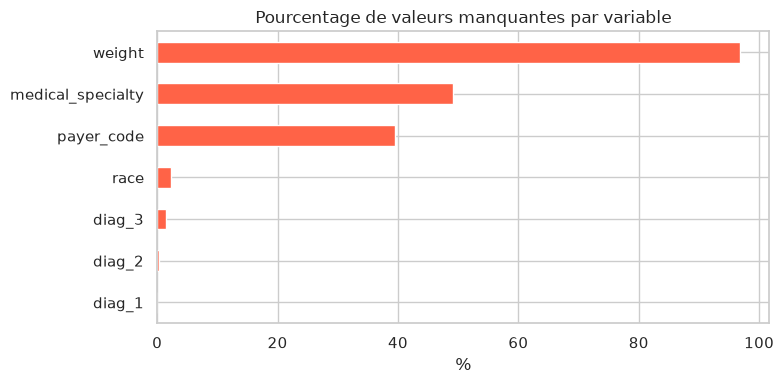

In [42]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
display(missing.round(2).to_frame("% de valeurs manquantes"))

plt.figure(figsize=(8, 4))
missing.sort_values().plot(kind="barh", color="tomato")
plt.title("Pourcentage de valeurs manquantes par variable")
plt.xlabel("%")
plt.tight_layout()
plt.show()

**Observations attendues :** `weight` est manquante à environ 97 %, `medical_specialty` à environ 49 %, `payer_code` à environ 40 %. `race` et les diagnostics (`diag_1/2/3`) ont très peu de valeurs manquantes. Ces proportions très différentes imposeront des **traitements différents** selon la variable (section 4).

## 3.2 Variable cible

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

readmitted
NO     53.9
>30    34.9
<30    11.2
Name: proportion, dtype: float64


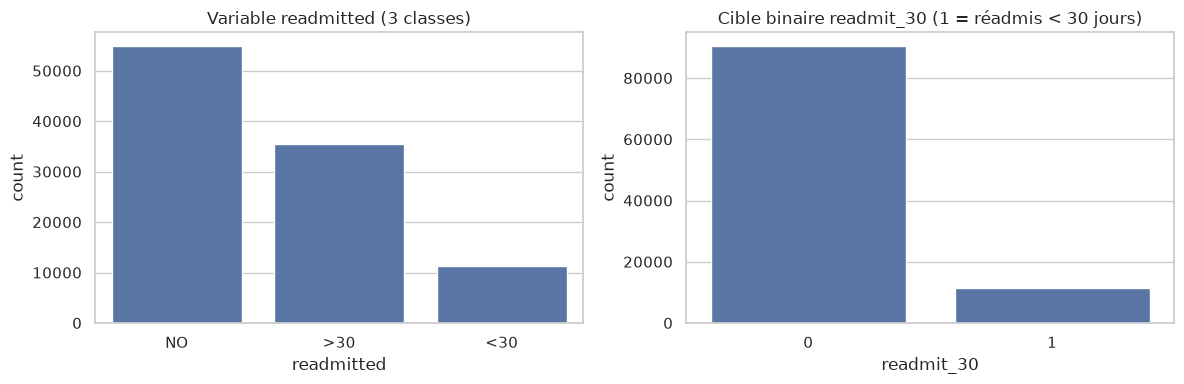

In [43]:
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)

print(df["readmitted"].value_counts())
print()
print(df["readmitted"].value_counts(normalize=True).round(3) * 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"], ax=axes[0])
axes[0].set_title("Variable readmitted (3 classes)")
sns.countplot(data=df, x="readmit_30", ax=axes[1])
axes[1].set_title("Cible binaire readmit_30 (1 = réadmis < 30 jours)")
plt.tight_layout()
plt.show()

**Observation :** la classe positive (`<30`) est **minoritaire (environ 11 %)**. Le jeu de données est donc **déséquilibré**, ce qui influencera le choix des métriques et des modèles (section 6).

## 3.3 Variables numériques : distributions

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0


Asymétrie (skewness) :
time_in_hospital       1.13
num_lab_procedures    -0.24
num_procedures         1.32
num_medications        1.33
number_outpatient      8.83
number_emergency      22.86
number_inpatient       3.61
number_diagnoses      -0.88
dtype: float64


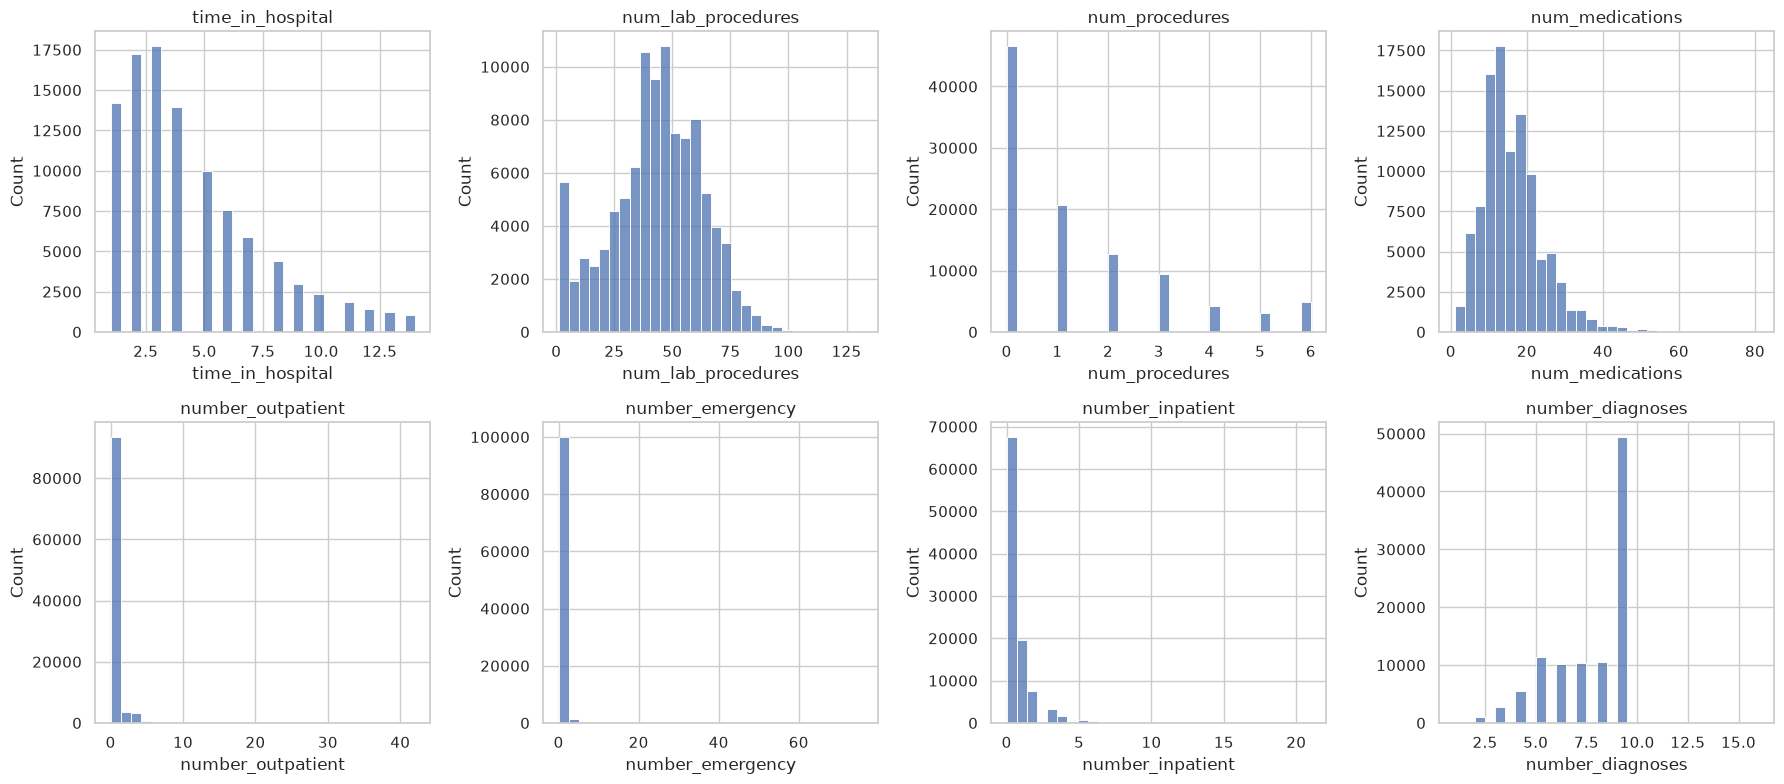

In [44]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

display(df[num_cols].describe().T.round(2))
print("Asymétrie (skewness) :")
print(df[num_cols].skew().round(2))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Observations attendues :**
- `number_outpatient`, `number_emergency`, `number_inpatient` sont **très asymétriques** : la grande majorité des patients ont 0 visite, avec une longue queue.
- `time_in_hospital`, `num_medications` et `num_lab_procedures` sont asymétriques à droite, mais de façon plus modérée.
- `number_diagnoses` est borné (de 1 à 16 environ) avec un pic autour de 9.

## 3.4 Valeurs aberrantes (boxplots et règle de l'IQR)

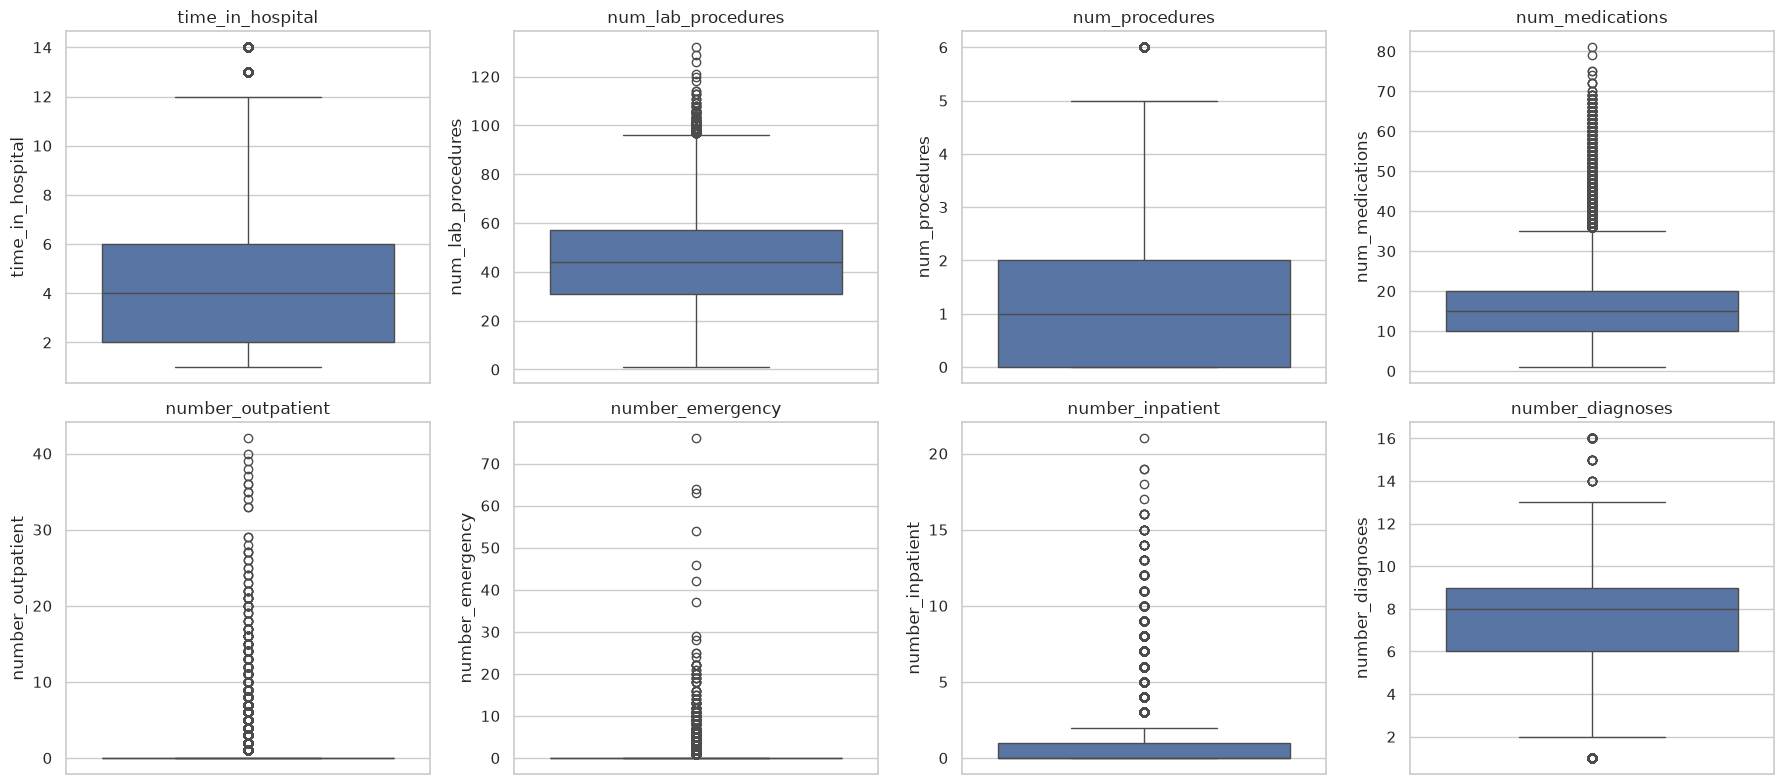

,% d'outliers (IQR)
time_in_hospital,2.21
num_lab_procedures,0.14
num_procedures,4.87
num_medications,2.51
number_outpatient,16.45
number_emergency,11.19
number_inpatient,6.93
number_diagnoses,0.28


In [45]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

def iqr_outlier_rate(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

pd.Series({c: iqr_outlier_rate(df[c]) for c in num_cols}).round(2).to_frame("% d'outliers (IQR)")

**Observation :** beaucoup de points sortent des moustaches. Pour les variables de comptage très concentrées sur 0, la règle de l'IQR (qui vaut alors 0) classe en "outlier" toute valeur non nulle : ce sont des **valeurs rares mais plausibles** (un patient très souvent hospitalisé existe réellement), pas des erreurs de saisie. Nous les traiterons avec précaution (section 4.4).

## 3.5 Variables catégorielles

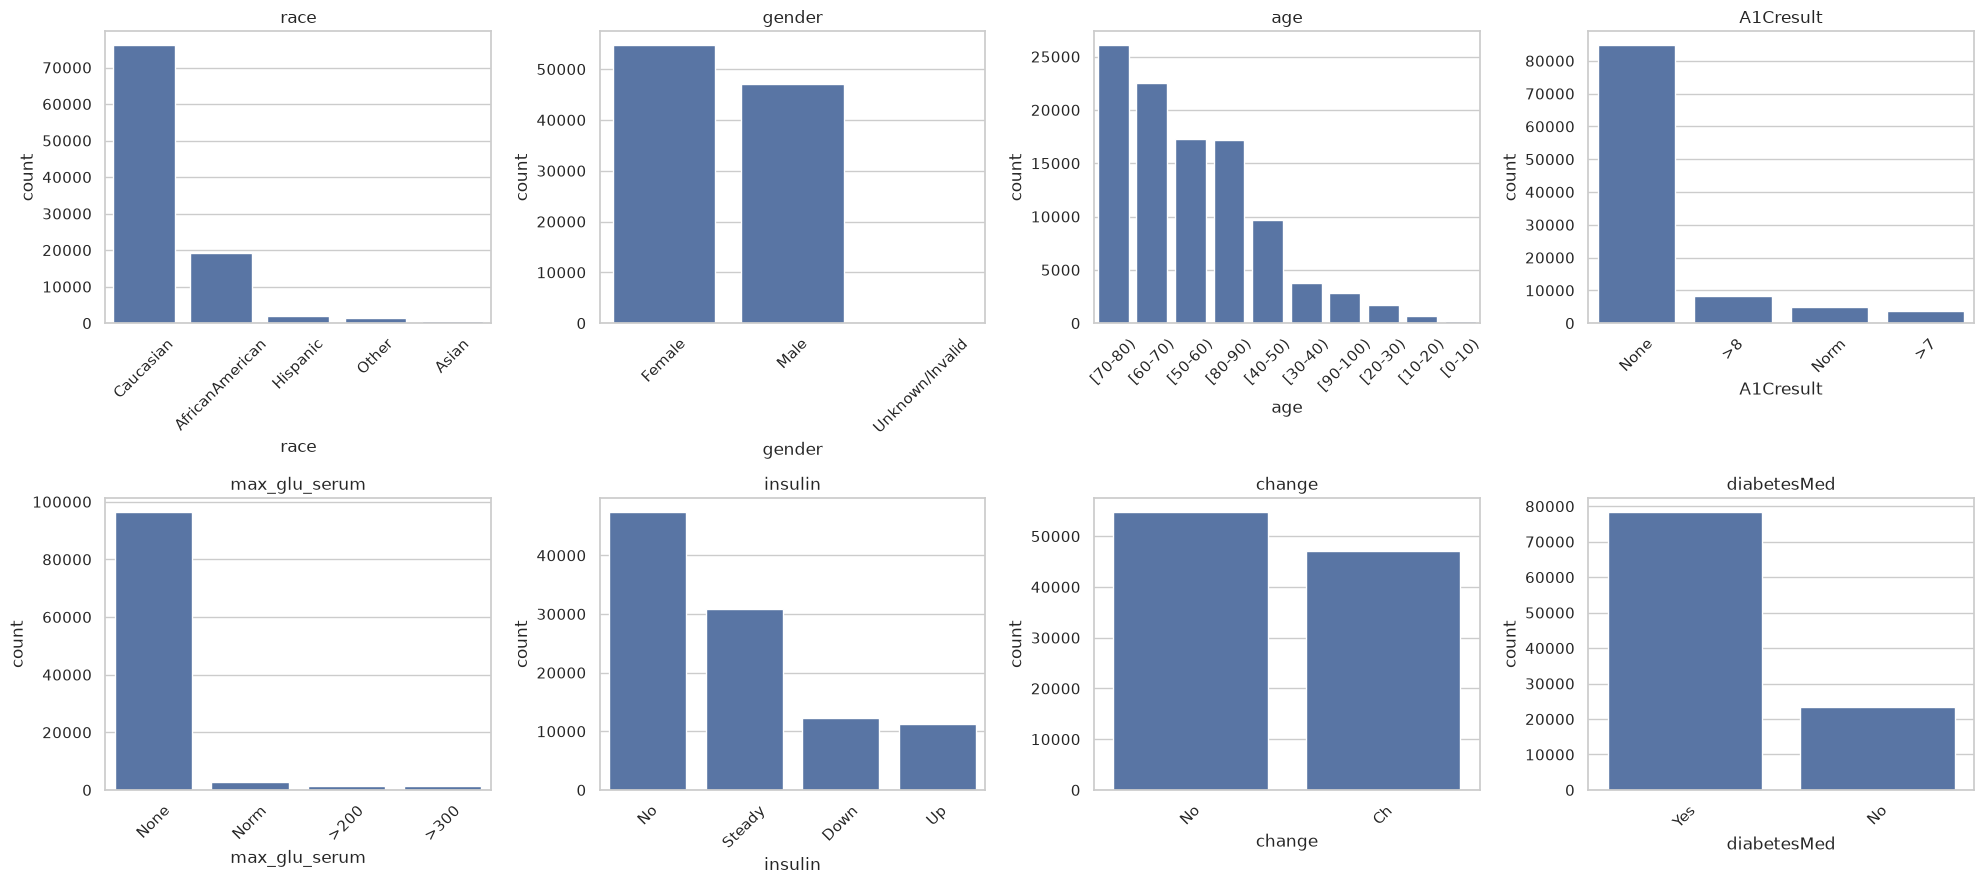

In [46]:
cat_cols_eda = ["race", "gender", "age", "A1Cresult", "max_glu_serum", "insulin", "change", "diabetesMed"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_cols_eda):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Observations attendues :**
- La population est majoritairement **Caucasienne** et âgée (pic entre 60 et 80 ans).
- `A1Cresult` et `max_glu_serum` valent "None" pour la grande majorité des séjours : l'examen n'a **pas été réalisé**. Ce "None" n'est pas un manquant à imputer, c'est une information (examen non fait).
- `insulin` est la molécule la plus utilisée.

## 3.6 Relations avec la cible (taux de réadmission < 30 jours)

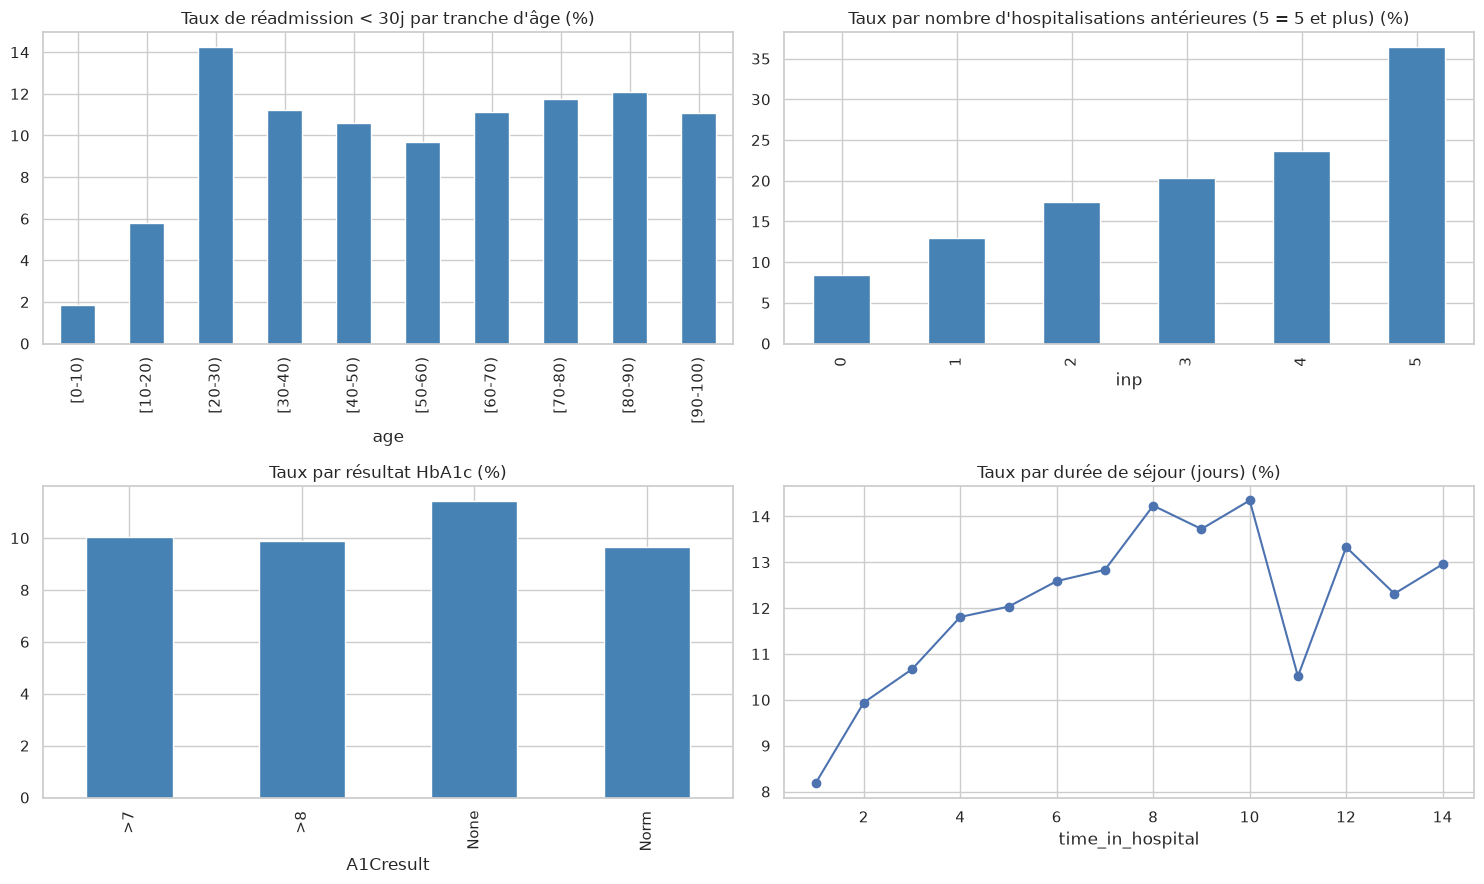

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

df.groupby("age")["readmit_30"].mean().mul(100).plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Taux de réadmission < 30j par tranche d'âge (%)")

df.assign(inp=df["number_inpatient"].clip(upper=5)).groupby("inp")["readmit_30"].mean().mul(100).plot(
    kind="bar", ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Taux par nombre d'hospitalisations antérieures (5 = 5 et plus) (%)")

df.groupby("A1Cresult")["readmit_30"].mean().mul(100).plot(kind="bar", ax=axes[1, 0], color="steelblue")
axes[1, 0].set_title("Taux par résultat HbA1c (%)")

df.groupby("time_in_hospital")["readmit_30"].mean().mul(100).plot(marker="o", ax=axes[1, 1])
axes[1, 1].set_title("Taux par durée de séjour (jours) (%)")

plt.tight_layout()
plt.show()

**Observations attendues :** le taux de réadmission **augmente fortement avec le nombre d'hospitalisations antérieures** (`number_inpatient`), et plus légèrement avec la durée du séjour. Les très jeunes et les très âgés présentent des taux un peu différents du reste de la population. L'effet de l'HbA1c est faible.

## 3.7 Corrélations entre variables numériques

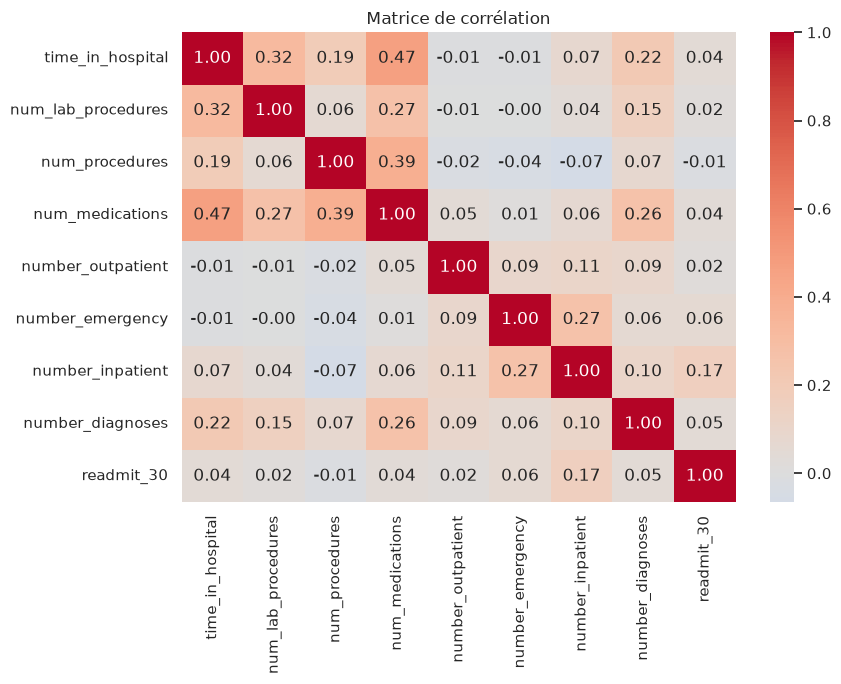

In [48]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols + ["readmit_30"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

**Observation :** les corrélations avec la cible sont **faibles** (la plus forte concerne `number_inpatient`). Il n'y a pas de corrélation extrême entre variables explicatives (la plus visible : `time_in_hospital` avec `num_medications` et `num_lab_procedures`), donc pas de problème sévère de multicolinéarité. Un score de prédiction très élevé ne doit pas être attendu : le problème est intrinsèquement difficile.

## 3.8 Détection d'anomalies et problèmes de qualité

In [49]:
print("1) Rencontres vs patients uniques :", len(df), "rencontres pour", df["patient_nbr"].nunique(), "patients")

print("\n2) Genre :")
print(df["gender"].value_counts())

print("\n3) Séjours terminés par décès ou soins palliatifs (codes", sorted(deceased_hospice_ids), ") :",
      df["discharge_disposition_id"].isin(deceased_hospice_ids).sum())

unk_adm = df["admission_type_id"].map(admission_type_map).eq("Unknown").mean() * 100
unk_src = df["admission_source_id"].map(admission_source_map).eq("Unknown").mean() * 100
unk_dis = df["discharge_disposition_id"].map(discharge_map).eq("Unknown").mean() * 100
print("\n3 bis) Codes déguisés en valeurs manquantes (NULL / Not Available / Not Mapped) :")
print(f"   admission_type : {unk_adm:.1f} %  |  admission_source : {unk_src:.1f} %  |  discharge : {unk_dis:.1f} %")

print("\n4) Colonnes constantes ou quasi constantes :")
med_cols = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
            "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
            "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
            "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
share_no = pd.Series({c: (df[c] == "No").mean() * 100 for c in med_cols}).sort_values(ascending=False)
display(share_no.round(2).to_frame("% de 'No'"))

1) Rencontres vs patients uniques : 101766 rencontres pour 71518 patients

2) Genre :
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

3) Séjours terminés par décès ou soins palliatifs (codes [11, 13, 14, 19, 20, 21] ) : 2423

3 bis) Codes déguisés en valeurs manquantes (NULL / Not Available / Not Mapped) :
   admission_type : 10.2 %  |  admission_source : 6.9 %  |  discharge : 4.6 %

4) Colonnes constantes ou quasi constantes :


,% de 'No'
citoglipton,100.00
examide,100.00
acetohexamide,100.00
metformin-pioglitazone,100.00
glimepiride-pioglitazone,100.00
metformin-rosiglitazone,100.00
troglitazone,100.00
glipizide-metformin,99.99
tolbutamide,99.98
miglitol,99.96


## 3.9 Synthèse de l'exploration

| # | Problème identifié | Conséquence | Traitement prévu |
|---|---|---|---|
| 1 | `weight` manquante à environ 97 % | Inexploitable | Suppression |
| 2 | `payer_code` (environ 40 % manquant) | Peu de lien clinique, beaucoup de trous | Suppression |
| 3 | `medical_specialty` (environ 49 % manquant) | Information potentiellement utile | Catégorie "Missing" + regroupement des modalités rares |
| 4 | `race`, `diag_1/2/3` : peu de manquants | Faible perte | "Unknown" pour `race`, groupement CIM-9 |
| 5 | Plusieurs séjours pour un même patient | **Fuite de données** entre train et test et non-indépendance | Garder une seule rencontre par patient |
| 6 | Patients décédés ou en soins palliatifs | Ne peuvent pas être réadmis : biais sur la cible | Suppression |
| 7 | Genre "Unknown/Invalid" (3 lignes) | Valeur invalide | Suppression |
| 8 | Médicaments quasi constants (`examide`, `citoglipton`...) | Aucune information | Suppression, remplacés par des variables agrégées |
| 9 | Variables de comptage très asymétriques et valeurs extrêmes | Sensibilité des modèles linéaires et du clustering | Écrêtage (winsorisation) + log |
| 10 | Variables à très nombreuses modalités (`diag_*`, ids) | Explosion de colonnes après encodage | Regroupement en catégories (ids via `IDS_mapping.csv`) |
| 10 bis | Codes `NULL` / `Not Available` / `Not Mapped` dans les 3 colonnes d'ids | Valeurs manquantes déguisées | Catégorie `Unknown` |
| 11 | Classes déséquilibrées | Accuracy trompeuse | `class_weight`, métriques adaptées |

# 4. Data Preparation

On travaille sur une **copie** (`df_clean`) pour conserver les données brutes intactes.

## 4.1 Suppression des lignes invalides ou non pertinentes

**Justifications :**
- *Genre invalide* : 3 lignes seulement, sans valeur exploitable : suppression plutôt qu'imputation.
- *Décès / soins palliatifs* (codes de sortie 11, 13, 14, 19, 20, 21, identifiés grâce aux descriptions `Expired` et `Hospice` de `IDS_mapping.csv`) : ces patients **ne peuvent pas être réadmis**. Les garder fausserait la cible (ils apparaissent "non réadmis" pour une raison sans lien avec la qualité des soins).
- *Une seule rencontre par patient* : un même patient peut apparaître plusieurs fois. Si ses séjours se retrouvent à la fois dans le train et dans le test, le modèle "reconnaît" le patient (**data leakage**) et les scores sont artificiellement gonflés. On garde la **première rencontre** de chaque patient. C'est plus simple et plus rigoureux qu'un `GroupShuffleSplit`, au prix d'une réduction du volume de données.

In [50]:
df_clean = df.copy()
n_start = len(df_clean)

# 1) Genre invalide
df_clean = df_clean[df_clean["gender"].isin(["Male", "Female"])]
n1 = len(df_clean)

# 2) Décès et soins palliatifs
df_clean = df_clean[~df_clean["discharge_disposition_id"].isin(deceased_hospice_ids)]
n2 = len(df_clean)

# 3) Une seule rencontre par patient (la première)
df_clean = df_clean.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")
n3 = len(df_clean)

print("Lignes de départ                     :", n_start)
print("Après suppression genre invalide     :", n1, "(-", n_start - n1, ")")
print("Après suppression décès/palliatif    :", n2, "(-", n1 - n2, ")")
print("Après 1 rencontre par patient        :", n3, "(-", n2 - n3, ")")

Lignes de départ                     : 101766
Après suppression genre invalide     : 101763 (- 3 )
Après suppression décès/palliatif    : 99340 (- 2423 )
Après 1 rencontre par patient        : 69987 (- 29353 )


## 4.2 Traitement des valeurs manquantes

| Variable | Choix | Pourquoi |
|---|---|---|
| `weight` | Suppression | Environ 97 % manquant : toute imputation serait inventée |
| `payer_code` | Suppression | Environ 40 % manquant et lien clinique faible (assurance) |
| `medical_specialty` | Catégorie `Missing`, puis regroupement des modalités rares en `Other` | Le fait que la spécialité ne soit pas renseignée peut être informatif ; trop de modalités sinon |
| `race` | Catégorie `Unknown` | Environ 2 % manquant : une catégorie dédiée évite de supprimer des lignes ou d'inventer une valeur |
| `diag_1` | Suppression des lignes manquantes (très peu) | Diagnostic principal : information essentielle |
| `diag_2`, `diag_3` | Catégorie `Missing` | Diagnostics secondaires : il est normal qu'ils soient parfois absents |

On évite l'imputation par la moyenne ou le mode : ces variables sont **catégorielles** et l'absence de valeur a souvent un sens.

In [51]:
df_clean = df_clean.drop(columns=["weight", "payer_code"])

df_clean["race"] = df_clean["race"].fillna("Unknown")
df_clean["medical_specialty"] = df_clean["medical_specialty"].fillna("Missing")

top_specialties = df_clean["medical_specialty"].value_counts().nlargest(10).index
df_clean["medical_specialty"] = df_clean["medical_specialty"].where(
    df_clean["medical_specialty"].isin(top_specialties), "Other")

df_clean = df_clean.dropna(subset=["diag_1"])

print("Valeurs manquantes restantes (hors diag_2 / diag_3) :")
remaining = df_clean.isna().sum()
print(remaining[remaining > 0])
print("\nTaille actuelle :", df_clean.shape)

Valeurs manquantes restantes (hors diag_2 / diag_3) :
diag_2     293
diag_3    1224
dtype: int64

Taille actuelle : (69977, 49)


## 4.3 Feature engineering

| Nouvelle variable | Construction | Intérêt |
|---|---|---|
| `age_num` | Milieu de la tranche d'âge (ex. `[60-70)` donne 65) | Transforme une variable ordinale textuelle en numérique exploitable par tous les algorithmes |
| `n_prior_visits` | `number_outpatient + number_emergency + number_inpatient` | Résume l'intensité de l'utilisation du système de santé |
| `n_meds_used` | Nombre de médicaments dont la valeur n'est pas `No` | Résume 23 colonnes très creuses en une seule variable |
| `n_meds_changed` | Nombre de médicaments `Up` ou `Down` | Mesure les ajustements de traitement |
| `diag_1_group`, `diag_2_group`, `diag_3_group` | Regroupement des codes CIM-9 en grandes familles (Diabète, Circulatoire, Respiratoire, Digestif, ...) | Passe de centaines de codes à environ 10 catégories interprétables |
| `admission_type`, `discharge_group`, `admission_source` | Regroupement des codes numériques via `IDS_mapping.csv` (section 2.4) ; les codes `NULL`, `Not Available`, `Not Mapped` forment une catégorie `Unknown` | Réduit les modalités, rend les variables lisibles et traite les manquants déguisés |

In [52]:
# Âge : milieu de la tranche
age_map = {"[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35, "[40-50)": 45,
           "[50-60)": 55, "[60-70)": 65, "[70-80)": 75, "[80-90)": 85, "[90-100)": 95}
df_clean["age_num"] = df_clean["age"].map(age_map)

# Historique de visites
df_clean["n_prior_visits"] = (df_clean["number_outpatient"] + df_clean["number_emergency"]
                              + df_clean["number_inpatient"])

# Médicaments agrégés
df_clean["n_meds_used"] = (df_clean[med_cols] != "No").sum(axis=1)
df_clean["n_meds_changed"] = df_clean[med_cols].isin(["Up", "Down"]).sum(axis=1)

# Regroupement des diagnostics CIM-9
def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    c = str(code)
    if c.startswith("V") or c.startswith("E"):
        return "Other"
    n = float(c)
    if 250 <= n < 251:
        return "Diabetes"
    if 390 <= n <= 459 or n == 785:
        return "Circulatory"
    if 460 <= n <= 519 or n == 786:
        return "Respiratory"
    if 520 <= n <= 579 or n == 787:
        return "Digestive"
    if 580 <= n <= 629 or n == 788:
        return "Genitourinary"
    if 140 <= n <= 239:
        return "Neoplasms"
    if 710 <= n <= 739:
        return "Musculoskeletal"
    if 800 <= n <= 999:
        return "Injury"
    return "Other"

for d in ["diag_1", "diag_2", "diag_3"]:
    df_clean[d + "_group"] = df_clean[d].apply(icd9_group)

# Regroupement des codes d'admission / sortie (dictionnaires construits depuis IDS_mapping.csv, section 2.4)
df_clean["admission_type"] = df_clean["admission_type_id"].map(admission_type_map).fillna("Unknown")
df_clean["discharge_group"] = df_clean["discharge_disposition_id"].map(discharge_map).fillna("Unknown")
df_clean["admission_source"] = df_clean["admission_source_id"].map(admission_source_map).fillna("Unknown")

df_clean[["age_num", "n_prior_visits", "n_meds_used", "n_meds_changed",
          "diag_1_group", "admission_type", "discharge_group", "admission_source"]].head()

,age_num,n_prior_visits,n_meds_used,n_meds_changed,diag_1_group,admission_type,discharge_group,admission_source
8,85,0,2,0,Circulatory,Emergency,Home,Transfer
9,95,0,2,0,Circulatory,Elective,Facility,Transfer
4,45,0,2,0,Neoplasms,Emergency,Home,Emergency
10,45,0,1,0,Diabetes,Emergency,Home,Emergency
5,55,0,1,0,Circulatory,Emergency,Home,Referral


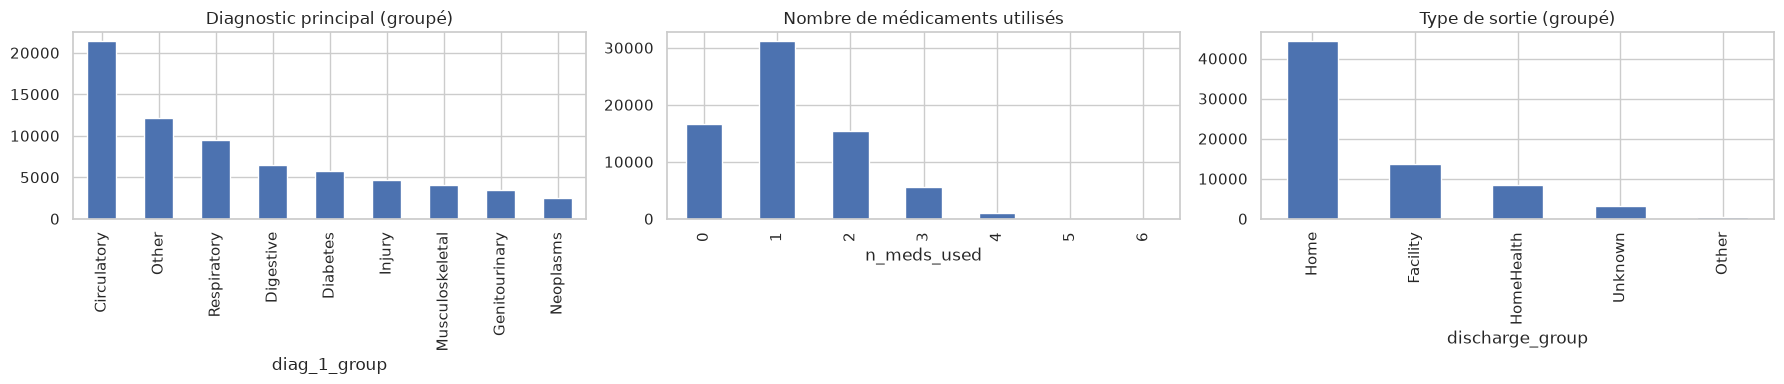

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
df_clean["diag_1_group"].value_counts().plot(kind="bar", ax=axes[0], title="Diagnostic principal (groupé)")
df_clean["n_meds_used"].value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Nombre de médicaments utilisés")
df_clean["discharge_group"].value_counts().plot(kind="bar", ax=axes[2], title="Type de sortie (groupé)")
plt.tight_layout()
plt.show()

## 4.4 Valeurs aberrantes

**Choix : écrêtage (winsorisation) au 99e percentile**, plutôt que suppression.

- Nous avons vu que les valeurs extrêmes sont **plausibles** (patients très suivis), pas des erreurs. Les supprimer ferait perdre des patients à haut risque, précisément ceux qui nous intéressent.
- L'écrêtage garde toutes les lignes mais **limite l'influence** des extrêmes sur les modèles sensibles (régression logistique, K-Means).
- Le 99e percentile est un seuil simple et reproductible.

In [54]:
cap_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses", "n_prior_visits"]

caps = {}
for c in cap_cols:
    caps[c] = df_clean[c].quantile(0.99)
    df_clean[c] = df_clean[c].clip(upper=caps[c])

print("Seuils d'écrêtage (99e percentile) :")
print(pd.Series(caps))
df_clean[cap_cols].describe().T.round(2)

Seuils d'écrêtage (99e percentile) :
time_in_hospital      13.0
num_lab_procedures    85.0
num_procedures         6.0
num_medications       44.0
number_outpatient      4.0
number_emergency       2.0
number_inpatient       3.0
number_diagnoses       9.0
n_prior_visits         6.0
dtype: float64


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,69977.0,4.26,2.91,1.0,2.0,3.0,6.0,13.0
num_lab_procedures,69977.0,42.82,19.75,1.0,31.0,44.0,57.0,85.0
num_procedures,69977.0,1.43,1.76,0.0,0.0,1.0,2.0,6.0
num_medications,69977.0,15.59,7.94,1.0,10.0,14.0,20.0,44.0
number_outpatient,69977.0,0.24,0.74,0.0,0.0,0.0,0.0,4.0
number_emergency,69977.0,0.09,0.34,0.0,0.0,0.0,0.0,2.0
number_inpatient,69977.0,0.16,0.51,0.0,0.0,0.0,0.0,3.0
number_diagnoses,69977.0,7.22,1.99,1.0,6.0,8.0,9.0,9.0
n_prior_visits,69977.0,0.52,1.14,0.0,0.0,0.0,1.0,6.0


## 4.5 Sauvegarde du fichier de données nettoyées
Ce fichier (lisible, avant encodage) fait partie des livrables.

In [55]:
NEW_DATA_DIR = Path("./Data/New_Data")
df_clean.to_csv(NEW_DATA_DIR / "diabetes_clean.csv", index=False)
print("Fichier diabetes_clean.csv enregistré :", df_clean.shape)

Fichier diabetes_clean.csv enregistré : (69977, 59)


## 4.6 Transformations : distributions, encodage

### Distributions (transformation logarithmique)
Les variables de visites sont très asymétriques. On applique `log(1 + x)` : elle **compresse la queue** tout en gérant les zéros (contrairement à `log(x)`). Cela aide la régression logistique et le K-Means, qui supposent des échelles et des distributions raisonnables. Les arbres et forêts n'en ont pas besoin, mais la transformation ne les pénalise pas (elle est monotone).

### Encodage des variables catégorielles
| Type | Variables | Méthode | Pourquoi |
|---|---|---|---|
| Binaire | `gender`, `change`, `diabetesMed` | 0 / 1 | Deux modalités seulement |
| Nominale | `race`, `medical_specialty`, groupes de diagnostics, admission, sortie, `A1Cresult`, `max_glu_serum`, `insulin`, `metformin` | **One-Hot** (`drop_first=True`) | Pas d'ordre naturel : un encodage ordinal (0, 1, 2...) créerait un faux ordre. `drop_first` évite la redondance entre colonnes |
| Ordinale | `age` | Milieu de tranche (`age_num`, déjà fait) | L'ordre est réel et la distance entre tranches est constante |

Les autres colonnes de médicaments sont retirées : elles sont quasi constantes (voir 3.8) et leur information est résumée par `n_meds_used` et `n_meds_changed`. On conserve `insulin` et `metformin`, les deux molécules les plus utilisées.

### Mise à l'échelle
La standardisation (`StandardScaler`) sera appliquée **uniquement quand l'algorithme en a besoin** (K-Means, régression logistique), et dans la partie classification **uniquement ajustée sur le jeu d'entraînement** (via un `Pipeline`) pour éviter toute fuite d'information.

In [56]:
df_prep = df_clean.copy()

# Transformation log
log_cols = ["number_outpatient", "number_emergency", "number_inpatient", "n_prior_visits"]
skew_before = df_prep[log_cols].skew()
for c in log_cols:
    df_prep[c] = np.log1p(df_prep[c])
skew_after = df_prep[log_cols].skew()
print(pd.DataFrame({"skew avant": skew_before, "skew après": skew_after}).round(2))

# Encodage binaire
df_prep["gender"] = (df_prep["gender"] == "Male").astype(int)
df_prep["change"] = (df_prep["change"] == "Ch").astype(int)
df_prep["diabetesMed"] = (df_prep["diabetesMed"] == "Yes").astype(int)

# Cible binaire
df_prep["readmit_30"] = (df_prep["readmitted"] == "<30").astype(int)

# Colonnes à retirer
other_meds = [m for m in med_cols if m not in ("insulin", "metformin")]
drop_cols = (["encounter_id", "patient_nbr", "age", "readmitted",
              "admission_type_id", "discharge_disposition_id", "admission_source_id",
              "diag_1", "diag_2", "diag_3"] + other_meds)
df_prep = df_prep.drop(columns=drop_cols)

# One-Hot
cat_cols = ["race", "medical_specialty", "diag_1_group", "diag_2_group", "diag_3_group",
            "admission_type", "discharge_group", "admission_source",
            "A1Cresult", "max_glu_serum", "insulin", "metformin"]
df_prep = pd.get_dummies(df_prep, columns=cat_cols, drop_first=True, dtype=int)

print("\nDimensions finales :", df_prep.shape)
print("Valeurs manquantes :", int(df_prep.isna().sum().sum()))
print("Colonnes non numériques :", list(df_prep.select_dtypes(exclude="number").columns))

                   skew avant  skew après
number_outpatient        3.55        2.77
number_emergency         4.06        3.61
number_inpatient         3.60        2.86
n_prior_visits           2.80        1.74

Dimensions finales : (69977, 80)
Valeurs manquantes : 0
Colonnes non numériques : []


In [57]:
df_prep.to_csv(NEW_DATA_DIR / "diabetes_prepared.csv", index=False)
print("Fichier diabetes_prepared.csv enregistré :", df_prep.shape)
df_prep.head()

Fichier diabetes_prepared.csv enregistré : (69977, 80)


,gender,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,change,diabetesMed,readmit_30,age_num,n_prior_visits,n_meds_used,n_meds_changed,race_Asian,race_Caucasian,race_Hispanic,race_Other,race_Unknown,medical_specialty_Emergency/Trauma,medical_specialty_Family/GeneralPractice,medical_specialty_InternalMedicine,medical_specialty_Missing,medical_specialty_Nephrology,medical_specialty_Orthopedics,medical_specialty_Orthopedics-Reconstructive,medical_specialty_Other,medical_specialty_Radiologist,...,diag_3_group_Genitourinary,diag_3_group_Injury,diag_3_group_Missing,diag_3_group_Musculoskeletal,diag_3_group_Neoplasms,diag_3_group_Other,diag_3_group_Respiratory,admission_type_Emergency,admission_type_Other,admission_type_Unknown,discharge_group_Home,discharge_group_HomeHealth,discharge_group_Other,discharge_group_Unknown,admission_source_Other,admission_source_Referral,admission_source_Transfer,admission_source_Unknown,A1Cresult_>8,A1Cresult_None,A1Cresult_Norm,max_glu_serum_>300,max_glu_serum_None,max_glu_serum_Norm,insulin_No,insulin_Steady,insulin_Up,metformin_No,metformin_Steady,metformin_Up
8,0,13,68,2,28,0.0,0.0,0.0,8,1,1,0,85,0.0,2,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0
9,0,12,33,3,18,0.0,0.0,0.0,8,1,1,0,95,0.0,2,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1,0,0
4,1,1,51,0,8,0.0,0.0,0.0,5,1,1,0,45,0.0,2,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0
10,0,9,47,2,17,0.0,0.0,0.0,9,0,1,0,45,0.0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0
5,1,3,31,6,16,0.0,0.0,0.0,9,0,1,0,55,0.0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1,0,1,0,0


# 5. Segmentation (Clustering)

## 5.1 Problématique
> Peut-on regrouper les séjours en **profils homogènes** de patients, selon leur âge, l'intensité de leur prise en charge et leur historique ?

## 5.2 Choix de la méthode et des variables
- **Algorithme : K-Means.** Simple, rapide sur environ 70 000 lignes et interprétable via les centres de clusters. Il suppose des clusters globulaires et des variables numériques à la même échelle, d'où la standardisation.
- **Variables :** uniquement des variables **numériques continues ou de comptage** (K-Means utilise la distance euclidienne, peu adaptée aux variables binaires/one-hot). 
- **La cible n'est pas utilisée** pour construire les clusters : nous la comparerons ensuite aux clusters pour interprétation.
- **Standardisation obligatoire** : sans elle, les variables de grande échelle (`num_lab_procedures`) domineraient les distances.

In [58]:
cluster_features = ["age_num", "time_in_hospital", "num_lab_procedures", "num_procedures",
                    "num_medications", "number_diagnoses", "n_prior_visits", "n_meds_used", "n_meds_changed"]

X_clu = df_prep[cluster_features]
X_clu_scaled = StandardScaler().fit_transform(X_clu)
print("Matrice de clustering :", X_clu_scaled.shape)

Matrice de clustering : (69977, 9)


## 5.3 Choix du nombre de clusters K
Deux critères complémentaires :
- **Méthode du coude (inertie)** : on cherche le point où le gain devient marginal.
- **Score de silhouette** (entre -1 et 1) : mesure la cohésion interne et la séparation entre clusters. Calculé sur un échantillon de 10 000 points pour limiter le temps de calcul.

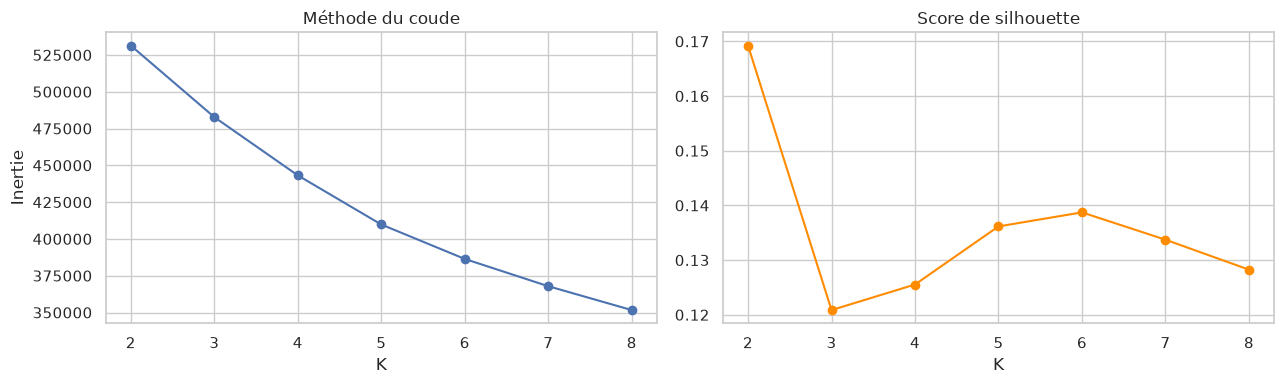

   K     inertie  silhouette
0  2  531385.524       0.169
1  3  482775.815       0.121
2  4  443195.736       0.126
3  5  409808.119       0.136
4  6  386400.296       0.139
5  7  367871.624       0.134
6  8  351648.840       0.128


In [59]:
k_values = range(2, 9)
inertias, silhouettes = [], []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_clu_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clu_scaled, labels, sample_size=10000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertie")
axes[1].plot(list(k_values), silhouettes, marker="o", color="darkorange")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("K")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"K": list(k_values), "inertie": inertias, "silhouette": silhouettes}).round(3))

**Choix de K :** le silhouette favorise souvent K = 2 (séparation grossière). Pour une segmentation **exploitable métier**, on peut préférer un K légèrement plus grand (3 ou 4) si le coude et le silhouette restent acceptables et que les profils obtenus sont **distincts et interprétables**. Modifiez la valeur de `K` ci-dessous selon vos graphiques et justifiez votre choix à l'oral.

In [60]:
K = 4   # à ajuster selon les graphiques ci-dessus

kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
df_seg = df_prep.copy()
df_seg["cluster"] = kmeans.fit_predict(X_clu_scaled)

print("Taille des clusters :")
print(df_seg["cluster"].value_counts().sort_index())
print("Silhouette (échantillon) :",
      round(silhouette_score(X_clu_scaled, df_seg["cluster"], sample_size=10000, random_state=RANDOM_STATE), 3))

Taille des clusters :
cluster
0    24715
1    11877
2    14554
3    18831
Name: count, dtype: int64
Silhouette (échantillon) : 0.126


## 5.4 Visualisation (ACP en 2D)
L'Analyse en Composantes Principales projette les données sur 2 axes uniquement pour **visualiser** les clusters. Elle n'a pas servi à les construire.

Variance expliquée par les 2 axes : [0.246 0.144] soit 39.0 %


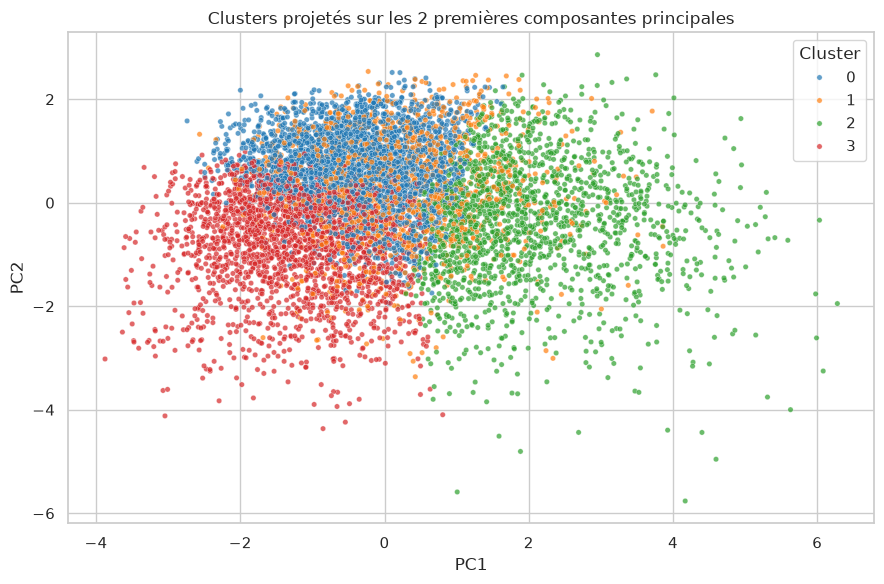

In [61]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_clu_scaled)
print("Variance expliquée par les 2 axes :", pca.explained_variance_ratio_.round(3), "soit", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(df_seg), size=min(8000, len(df_seg)), replace=False)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=coords[sample_idx, 0], y=coords[sample_idx, 1],
                hue=df_seg["cluster"].values[sample_idx], palette="tab10", s=15, alpha=0.7)
plt.title("Clusters projetés sur les 2 premières composantes principales")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 5.5 Profilage des clusters
On compare les **moyennes** des variables par cluster pour donner un sens métier à chaque groupe, et on regarde le **taux de réadmission < 30 jours** de chacun (variable non utilisée pour la segmentation).

In [62]:
# Profil avec les variables en échelle d'origine (avant log) pour faciliter la lecture
profile = df_clean.loc[df_seg.index, cluster_features].copy()
profile["cluster"] = df_seg["cluster"]
profile_means = profile.groupby("cluster").mean().round(2)
profile_means["effectif"] = df_seg["cluster"].value_counts().sort_index()
profile_means["taux_readmit_30 (%)"] = (df_seg.groupby("cluster")["readmit_30"].mean() * 100).round(2)

display(profile_means.style.background_gradient(cmap="Blues", axis=0))

,age_num,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,n_prior_visits,n_meds_used,n_meds_changed,effectif,taux_readmit_30 (%)
cluster,,,,,,,,,,,
0,71.970000,3.590000,39.220000,1.120000,13.250000,8.200000,0.070000,0.880000,0.100000,24715,8.430000
1,67.400000,4.070000,44.450000,1.060000,15.760000,7.950000,2.450000,1.270000,0.270000,11877,12.650000
2,66.100000,7.540000,55.830000,2.650000,24.960000,8.080000,0.230000,1.690000,0.620000,14554,10.550000
3,55.130000,2.740000,36.440000,1.120000,11.300000,4.810000,0.140000,1.150000,0.200000,18831,6.170000


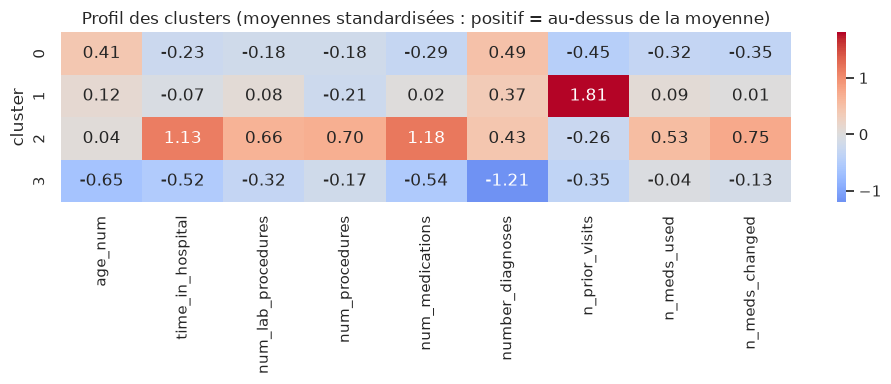

In [63]:
scaled_profile = pd.DataFrame(X_clu_scaled, columns=cluster_features)
scaled_profile["cluster"] = df_seg["cluster"].values
plt.figure(figsize=(10, 4))
sns.heatmap(scaled_profile.groupby("cluster").mean(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Profil des clusters (moyennes standardisées : positif = au-dessus de la moyenne)")
plt.tight_layout()
plt.show()

## 5.6 Interprétation des clusters

La heatmap (moyennes standardisées) et le tableau de profilage (valeurs d'origine) font apparaître 4 profils distincts. Le taux de réadmission global de l'échantillon est d'environ 9 %.

| Cluster | Profil | Effectif | Taux de réadmission < 30j |
|---|---|---|---|
| 1 | **Patients récurrents** : historique de visites très élevé (2,45 visites antérieures en moyenne contre 0,07 à 0,23 ailleurs), reste proche de la moyenne | 11 877 (17 %) | **12,65 %** |
| 2 | **Séjours lourds et complexes** : séjour long (7,5 jours), environ 25 médicaments, 2,7 procédures, davantage de changements de traitement | 14 554 (21 %) | 10,55 % |
| 0 | **Patients âgés à prise en charge légère** : âge moyen de 72 ans, nombreux diagnostics, mais séjours courts, peu de médicaments et peu d'historique | 24 715 (35 %) | 8,43 % |
| 3 | **Cas simples** : patients plus jeunes (55 ans), environ 5 diagnostics seulement, séjours courts, peu de traitements | 18 831 (27 %) | **6,17 %** |

**Lecture :** la segmentation est structurée par trois axes : l'historique de fréquentation du système de soins (cluster 1), l'intensité de la prise en charge (cluster 2) et la complexité diagnostique (clusters 0 et 3).

**Lien avec la réadmission :** bien que la cible n'ait pas servi à construire les clusters, leurs taux de réadmission diffèrent nettement : le cluster 1 est environ 2 fois plus à risque que le cluster 3 (12,65 % contre 6,17 %). Les clusters 1 et 2 sont au-dessus du taux global, le cluster 3 est nettement en dessous. Cela confirme que l'historique de visites et l'intensité de la prise en charge sont liés au risque de réadmission, ce que la classification exploitera (section 6).

**Nuances :** le cluster 1 est défini en grande partie par `n_prior_visits`, qui est lui-même l'un des meilleurs prédicteurs de la réadmission : son sur-risque est donc en partie attendu. Les écarts restent modérés (le cluster 2 est seulement 1,5 point au-dessus de la moyenne) : aucun cluster ne permet à lui seul de prédire une réadmission.

**Limites :** K-Means impose des groupes sphériques et n'utilise pas les variables catégorielles (diagnostics, type de sortie). Le chevauchement visible sur la projection ACP est fréquent sur des données médicales réelles.

# 6. Classification

## 6.1 Problématique
> Prédire si un patient sera **réadmis en moins de 30 jours** (`readmit_30` = 1) à partir des informations connues à la sortie.

## 6.2 Séparation train / test
- Découpage **80 % / 20 %** avec **stratification** (`stratify=y`) pour conserver la même proportion de réadmissions dans les deux ensembles (indispensable avec des classes déséquilibrées).
- Il n'y a pas de fuite entre patients puisqu'on a gardé **une seule rencontre par patient** (section 4.1).

In [64]:
X = df_prep.drop(columns="readmit_30")
y = df_prep["readmit_30"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Taux de positifs (train) :", round(y_train.mean() * 100, 2), "%")
print("Taux de positifs (test)  :", round(y_test.mean() * 100, 2), "%")

Train : (55981, 79) | Test : (13996, 79)
Taux de positifs (train) : 8.98 %
Taux de positifs (test)  : 8.98 %


## 6.3 Baseline
Avant tout modèle, on mesure un **classifieur naïf** qui prédit toujours la classe majoritaire. Il sert de référence : un modèle utile doit faire mieux sur les métriques adaptées.

In [65]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_base = baseline.predict(X_test)
print("Baseline : accuracy =", round(accuracy_score(y_test, pred_base), 3),
      "| recall classe 1 =", round(recall_score(y_test, pred_base), 3),
      "| F1 classe 1 =", round(f1_score(y_test, pred_base), 3))

Baseline : accuracy = 0.91 | recall classe 1 = 0.0 | F1 classe 1 = 0.0


**Lecture :** l'accuracy de la baseline est élevée (environ 89 %) alors que son rappel est **nul**. Cela confirme que l'accuracy est inadaptée ici.

## 6.4 Modèles choisis

| Modèle | Pourquoi | Gestion du déséquilibre |
|---|---|---|
| **Régression logistique** | Simple, rapide, **interprétable** (coefficients). Nécessite des variables standardisées (via un `Pipeline`) | `class_weight="balanced"` |
| **Arbre de décision** (profondeur limitée) | Très lisible, capte des interactions non linéaires. Profondeur limitée pour éviter le sur-apprentissage | `class_weight="balanced"` |
| **Forêt aléatoire** | Combine de nombreux arbres : plus robuste, gère bien les variables mixtes, fournit l'importance des variables | `class_weight="balanced"` |

`class_weight="balanced"` pénalise davantage les erreurs sur la classe minoritaire. C'est plus simple que le sur-échantillonnage (SMOTE) et n'invente pas de données synthétiques.

In [ ]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=20, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE),
}

## 6.5 Validation croisée (sur le train uniquement)
Une validation croisée stratifiée à 5 plis donne une estimation **plus stable** de la performance (ROC-AUC) et permet de vérifier l'absence de sur-apprentissage avant de toucher au jeu de test.

In [67]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:22s} ROC-AUC CV : {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression    ROC-AUC CV : 0.642 (+/- 0.004)
Decision Tree          ROC-AUC CV : 0.624 (+/- 0.006)
Random Forest          ROC-AUC CV : 0.644 (+/- 0.004)


## 6.6 Entraînement final et évaluation sur le jeu de test

In [68]:
fitted, results, probas = {}, {}, {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    probas[name] = proba
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    }

results_df = pd.DataFrame(results).T.round(3)
display(results_df)
print("Rappel : le PR-AUC d'un classifieur aléatoire vaut environ", round(y_test.mean(), 3))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.659,0.136,0.523,0.216,0.635,0.148
Decision Tree,0.603,0.125,0.570,0.205,0.617,0.137
Random Forest,0.648,0.133,0.527,0.212,0.638,0.154


Rappel : le PR-AUC d'un classifieur aléatoire vaut environ 0.09


### Métriques utilisées et pourquoi
| Métrique | Signification | Utilité ici |
|---|---|---|
| **Recall (rappel)** | Part des vrais réadmis détectés | Prioritaire : manquer un patient à risque est coûteux |
| **Precision** | Part des alertes qui sont de vraies réadmissions | Évite de surcharger l'hôpital de fausses alertes |
| **F1** | Compromis précision / rappel | Résumé pour classe minoritaire |
| **ROC-AUC** | Capacité à classer un positif au-dessus d'un négatif, indépendamment du seuil | Compare les modèles globalement |
| **PR-AUC** | Aire sous la courbe précision-rappel | Plus informative que le ROC-AUC quand la classe positive est rare |
| Accuracy | Part de bonnes prédictions | **À ne pas utiliser seule** (voir baseline) |

## 6.7 Courbes ROC et Précision-Rappel

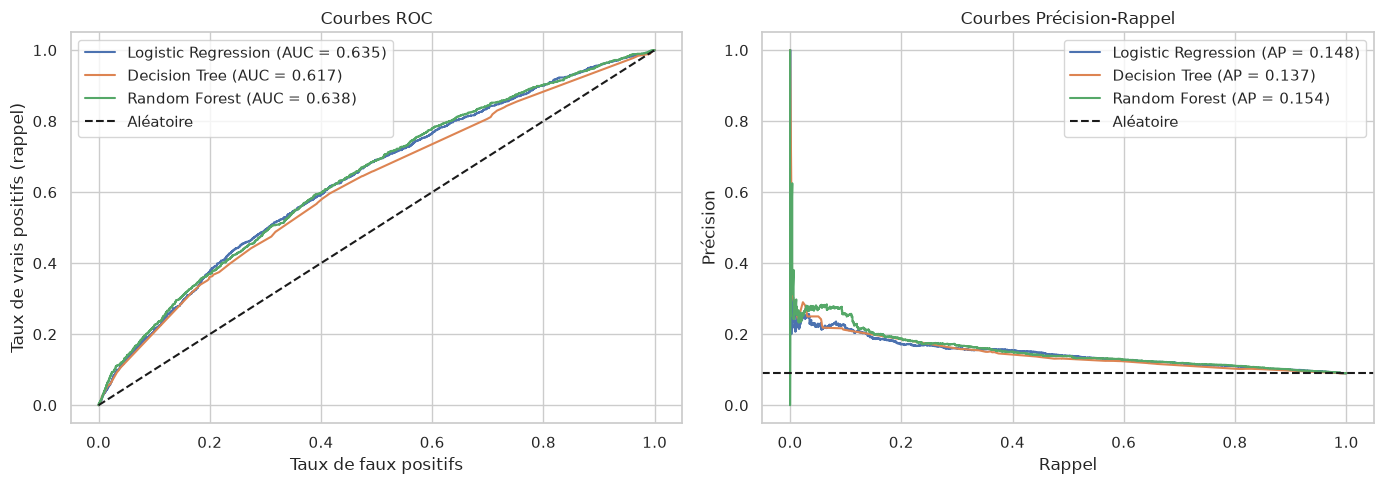

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Aléatoire")
axes[0].set_title("Courbes ROC")
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Taux de vrais positifs (rappel)")
axes[0].legend()

for name, proba in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP = {results[name]['PR-AUC']:.3f})")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Aléatoire")
axes[1].set_title("Courbes Précision-Rappel")
axes[1].set_xlabel("Rappel")
axes[1].set_ylabel("Précision")
axes[1].legend()

plt.tight_layout()
plt.show()

**Lecture des courbes :**
- **Courbes ROC :** les trois modèles se situent clairement au-dessus de la diagonale (hasard), donc ils captent un signal réel. La régression logistique et la forêt aléatoire sont presque superposées, l'arbre est un peu en dessous. Les courbes restent proches de la diagonale (AUC entre 0,62 et 0,64) : le pouvoir discriminant est **modeste**.
- **Courbes précision-rappel :** elles restent peu au-dessus de la ligne de base (taux de réadmission d'environ 9 %). La précision est d'environ 0,2 à 0,28 pour les patients classés en tête (rappel inférieur à 0,2), puis décroît vers 0,09 quand on cherche à tout détecter. Les pics à gauche de la courbe (précision proche de 1 pour un rappel quasi nul) viennent d'un tout petit nombre de patients et ne sont pas fiables.
- **Conclusion :** aucun modèle ne se détache nettement. Le choix entre eux repose donc sur des critères secondaires (interprétabilité, simplicité) plutôt que sur la performance.

# 7. Évaluation et interprétation des résultats

## 7.1 Meilleur modèle : matrice de confusion et rapport détaillé
Le meilleur modèle est choisi sur le **ROC-AUC du jeu de test** (indépendant du seuil).

Meilleur modèle : Random Forest

                          precision    recall  f1-score   support

Pas de réadmission < 30j       0.93      0.66      0.77     12739
       Réadmission < 30j       0.13      0.53      0.21      1257

                accuracy                           0.65     13996
               macro avg       0.53      0.59      0.49     13996
            weighted avg       0.86      0.65      0.72     13996



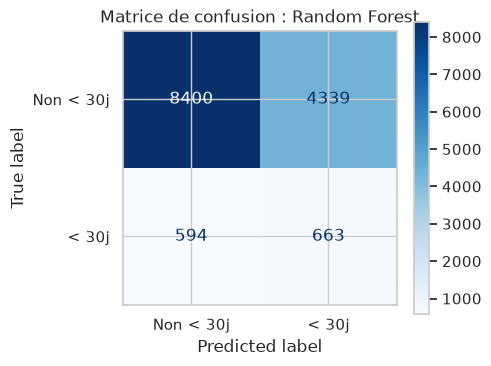

In [70]:
best_name = results_df["ROC-AUC"].idxmax()
print("Meilleur modèle :", best_name)

best_proba = probas[best_name]
best_pred = (best_proba >= 0.5).astype(int)

print()
print(classification_report(y_test, best_pred, target_names=["Pas de réadmission < 30j", "Réadmission < 30j"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["Non < 30j", "< 30j"], cmap="Blues", ax=ax)
ax.set_title(f"Matrice de confusion : {best_name}")
plt.tight_layout()
plt.show()

**Comment lire la matrice :** la case en bas à gauche (faux négatifs) correspond aux patients réadmis que le modèle n'a pas détectés ; la case en haut à droite (faux positifs) aux fausses alertes. Avec `class_weight="balanced"`, le modèle accepte plus de faux positifs pour détecter davantage de vrais réadmis : le rappel monte, la précision reste faible, et l'accuracy baisse par rapport à la baseline. **C'est un compromis voulu**, pas un défaut.

## 7.2 Impact du seuil de décision
Le seuil de 0,5 n'est pas sacré. On peut l'ajuster selon le coût relatif d'une fausse alerte et d'un patient manqué.

In [71]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (best_proba >= t).astype(int)
    rows.append({"seuil": t,
                 "precision": precision_score(y_test, pred_t, zero_division=0),
                 "recall": recall_score(y_test, pred_t),
                 "f1": f1_score(y_test, pred_t),
                 "patients signalés (%)": pred_t.mean() * 100})
display(pd.DataFrame(rows).round(3))

,seuil,precision,recall,f1,patients signalés (%)
0,0.3,0.092,0.989,0.168,96.656
1,0.4,0.105,0.852,0.188,72.549
2,0.5,0.133,0.527,0.212,35.739
3,0.6,0.203,0.150,0.172,6.616
4,0.7,0.256,0.008,0.015,0.279


## 7.3 Importance des variables
On regarde quelles variables influencent le plus la prédiction pour **interpréter** le modèle (et pas seulement le scorer).

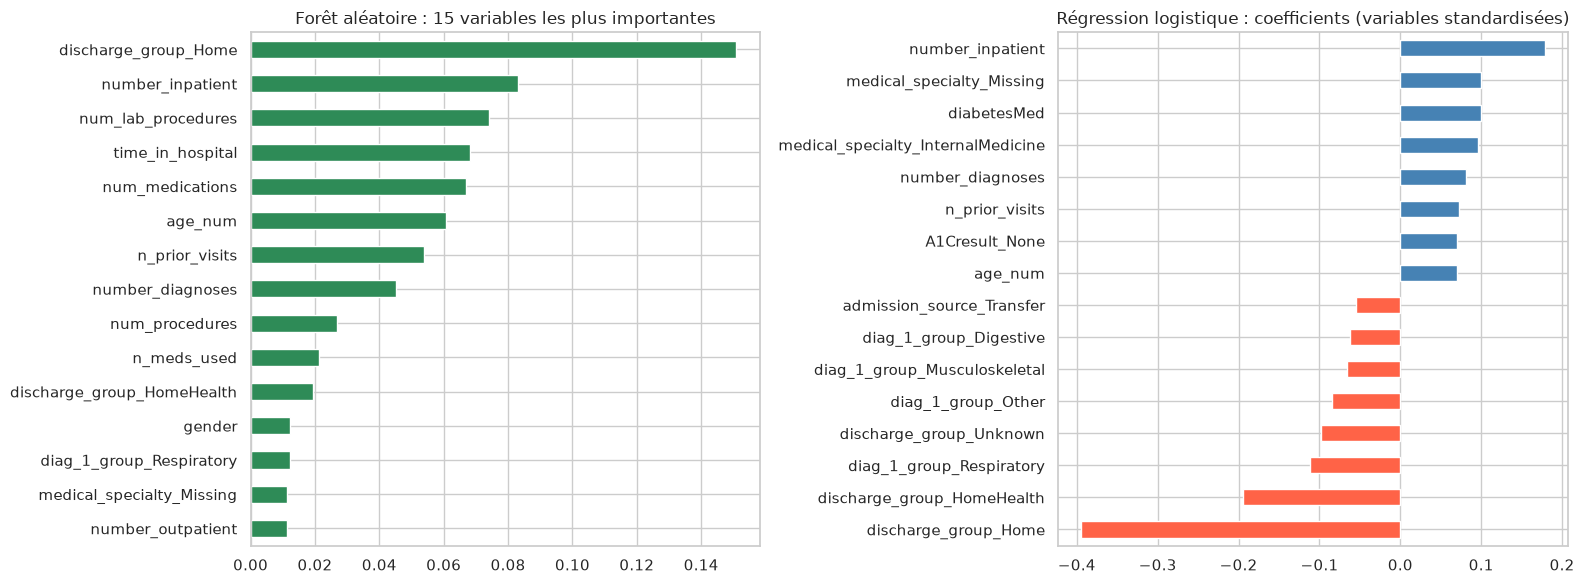

In [ ]:
rf = fitted["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).nlargest(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
importances.plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Forêt aléatoire : 15 variables les plus importantes")

lr = fitted["Logistic Regression"][-1]
coefs = pd.Series(lr.coef_[0], index=X.columns).sort_values()
extremes = pd.concat([coefs.head(8), coefs.tail(8)])
extremes.plot(kind="barh", ax=axes[1], color=["tomato" if v < 0 else "steelblue" for v in extremes])
axes[1].set_title("Régression logistique : coefficients (variables standardisées)")
plt.tight_layout()
plt.show()

## 7.4 Interprétation générale

**1. Performance du meilleur modèle (Random Forest).**
Avec le seuil par défaut de 0,5, le modèle détecte **53 % des réadmissions < 30 jours** (rappel), mais seulement **13 % de ses alertes sont de vraies réadmissions** (précision), pour un F1 de 0,21, un ROC-AUC de **0,638** et un PR-AUC de **0,154** (contre 0,09 pour un classifieur aléatoire, soit environ 1,7 fois mieux). Sa précision est environ **1,5 fois supérieure au hasard** (le taux de réadmission est d'environ 9 %), donc le modèle capte un vrai signal, mais modeste.
Son accuracy (0,65) est inférieure à celle de la baseline (environ 0,91). C'est attendu et voulu : avec `class_weight="balanced"`, le modèle accepte de nombreuses fausses alertes pour détecter davantage de patients à risque, alors que la baseline obtient son score en ne détectant personne (rappel nul).
Avec le seuil par défaut de 0,5, le modèle détecte **53 % des réadmissions < 30 jours** (rappel), mais seulement **13 % de ses alertes sont de vraies réadmissions** (précision), pour un F1 de 0,21, un ROC-AUC de **0,638** et un PR-AUC de **0,154** (contre 0,09 pour un classifieur aléatoire, soit environ 1,7 fois mieux).

**2. Choix du seuil de décision.**
Le tableau de seuils montre un compromis net entre rappel et nombre d'alertes :
- **Seuil 0,3 à 0,4 :** rappel de 85 à 99 %, mais 73 à 97 % des patients sont signalés. Le modèle ne trie plus rien : c'est inutilisable en pratique.
- **Seuil 0,5 :** compromis, avec 53 % des réadmissions détectées en signalant 36 % des patients.
- **Seuil 0,6 :** seulement 6,6 % des patients sont signalés, avec une précision de 20 % (environ **2,3 fois le taux de base**), mais le rappel tombe à 15 %.
- **Seuil 0,7 :** quasiment aucune alerte (0,3 %), inutilisable.
Le seuil optimal dépend de la **capacité de suivi de l'hôpital** : un seuil de 0,6 convient à un suivi coûteux ciblant très peu de patients, un seuil de 0,5 à un suivi léger et peu coûteux.

**3. Variables les plus influentes.**
- **Le type de sortie est le facteur dominant.** `discharge_group_Home` arrive en tête de la forêt aléatoire et porte le coefficient négatif le plus fort en régression logistique ; `discharge_group_HomeHealth` va dans le même sens. Les coefficients se lisent par rapport à la modalité de référence supprimée par `drop_first`, ici `Facility` (transfert vers un autre établissement). Les patients sortis à domicile sont donc moins réadmis que ceux transférés vers un établissement de soins, ce qui est plausible : un transfert signale souvent un état plus grave.
- **L'historique d'hospitalisations** (`number_inpatient`, `n_prior_visits`) est le meilleur prédicteur positif en régression logistique et figure dans le haut du classement de la forêt. Cela rejoint l'exploration (3.6) et le cluster 1 de la segmentation (12,65 % de réadmission).
- **Les variables d'intensité de prise en charge** (`num_lab_procedures`, `time_in_hospital`, `num_medications`, `number_diagnoses`) et `age_num` complètent le haut du classement de la forêt. Elles correspondent au cluster 2 (séjours lourds).
- **Effets secondaires** : quelques groupes de diagnostics (respiratoire, digestif, musculo-squelettique) et `admission_source_Transfer` sont associés à un risque plus faible, mais avec des coefficients faibles.

**Précautions d'interprétation :**
- L'importance des variables d'une forêt aléatoire tend à **favoriser les variables continues**, qui offrent beaucoup de seuils de découpage. Les cinq variables continues placées juste après le type de sortie sont donc en partie avantagées, ce qui explique qu'elles pèsent moins en régression logistique.
- `number_inpatient` et `n_prior_visits` sont **corrélées** : leur importance est partagée entre les deux.
- Ces résultats décrivent des **associations, pas des causes** : sortir à domicile ne protège pas en soi, cela reflète un patient dont l'état est moins grave.

**4. Comparaison des modèles.**

| Modèle | ROC-AUC (validation croisée) | ROC-AUC (test) | PR-AUC (test) | Rappel (test) |
|---|---|---|---|---|
| Régression logistique | 0,642 (+/- 0,004) | 0,635 | 0,148 | 0,523 |
| Arbre de décision | 0,624 (+/- 0,006) | 0,617 | 0,137 | 0,570 |
| Forêt aléatoire | 0,644 (+/- 0,004) | 0,638 | 0,154 | 0,527 |

- **Pas de sur-apprentissage :** les scores de validation croisée et de test sont très proches (écart d'environ 0,005 à 0,007) et les écarts-types sont faibles. Les modèles généralisent de façon stable.
- **Régression logistique et forêt aléatoire sont équivalentes :** leur écart de ROC-AUC (0,003) est inférieur à l'écart-type de la validation croisée (0,004). La forêt est retenue comme "meilleure" au sens strict du ROC-AUC, mais la différence n'est pas significative. Cela indique que les relations entre variables et cible sont **essentiellement simples** : la complexité supplémentaire de la forêt n'apporte presque rien. À performance égale, la régression logistique est préférable pour son **interprétabilité**.
- **L'arbre de décision est le plus faible** (ROC-AUC 0,617), ce qui est attendu pour un arbre unique de profondeur limitée. Son rappel plus élevé (0,570) ne traduit pas un meilleur modèle : à seuil fixe de 0,5, il signale simplement plus de patients, avec une précision plus basse (0,125).
- **L'accuracy ne départage pas les modèles** (0,60 à 0,66, toutes inférieures à la baseline d'environ 0,91), pour la raison expliquée plus haut.

**5. Lien avec la segmentation.**
Les deux analyses convergent : les facteurs que le modèle juge importants (historique d'hospitalisations, intensité de la prise en charge) sont ceux qui distinguent les clusters les plus à risque (clusters 1 et 2) du cluster le moins à risque (cluster 3, 6,17 %).

**6. Utilité pratique et limites.**
Le modèle est utile comme **score de priorisation** (par exemple concentrer un appel de suivi sur les 6 à 7 % de patients les mieux classés), pas comme outil de décision autonome : avec une précision de 13 à 20 %, la grande majorité des alertes sont de fausses alertes. Cette performance limitée vient surtout des données : elles décrivent le séjour mais pas le contexte social, le suivi après sortie ou l'observance du traitement, qui pèsent fortement sur une réadmission.

# 8. Conclusion et limites

**Synthèse de la démarche :**
- Exploration : données déséquilibrées, nombreux manquants structurels, doublons de patients, variables très asymétriques.
- Préparation : nettoyage justifié (suppression des cas invalides, 1 séjour par patient), gestion différenciée des manquants, feature engineering (âge, diagnostics groupés, médicaments agrégés), écrêtage et log, encodage One-Hot.
- Segmentation : K-Means sur variables numériques standardisées, K choisi avec coude et silhouette, clusters profilés.
- Classification : 3 modèles comparés avec gestion du déséquilibre, évalués avec des métriques adaptées.

**Limites :**
- Données de 1999 à 2008 : pratiques médicales potentiellement dépassées.
- Garder une seule rencontre par patient réduit la taille des données et ne modélise pas l'historique complet.
- Pas d'optimisation poussée des hyperparamètres (choix volontaire de simplicité).
- Performance plafonnée par l'information disponible.

**Pistes d'amélioration :** recherche d'hyperparamètres (`GridSearchCV`), modèles de boosting (XGBoost, LightGBM), rééchantillonnage (SMOTE), clustering mixte (K-Prototypes) incluant les variables catégorielles, optimisation du seuil selon un coût métier.